# Course 11: On-Device AI
## Session 12: Learning on the device, privacy, and the capstone

**Goal:** personalize a model on the device from 20 examples by updating all of it, its last layer or only its biases, measure the training memory each needs, and run federated averaging over five simulated phones with compressed updates.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. A pretrained model meets a new user
A model trained before shipping meets users whose data look different. We pretrain a small CNN on 650 of scikit-learn's digits (upsampled to 16 × 16) in their standard style. A new **user** writes differently: we simulate this by rotating the remaining digits by 25° and thickening their strokes. The digits used for pretraining never appear in the user's data. The real case would be a person's handwriting, voice or photos on their own phone; the shift here is **synthetic**.

CNN with 38,282 parameters, pretrained in 2 s
accuracy on the same 500 digits: standard style 0.960, the user's style 0.588; on the user's 350 test digits 0.589


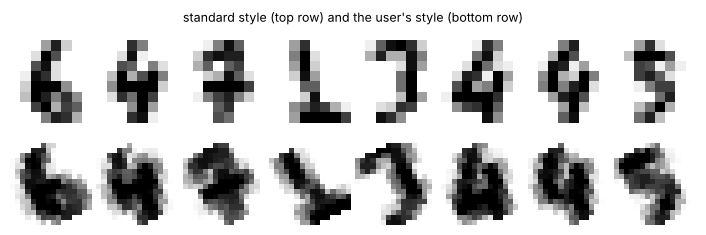

In [1]:
import time, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import ndimage
from sklearn.datasets import load_digits

t_start = time.time()
torch.set_num_threads(1); torch.manual_seed(0); np.random.seed(0)
X8, y = load_digits(return_X_y=True)
X = np.kron(X8.reshape(-1, 8, 8) / 16.0, np.ones((1, 2, 2)))          # 16 x 16, values in [0, 1]
perm = np.random.default_rng(0).permutation(len(X))
pre_idx, pool_idx = perm[:650], perm[650:]                             # pretraining digits / everyone else's digits

def style(imgs, rot=0.0, thick=0, zoom=1.0, shift=(0, 0)):              # a synthetic "handwriting style"
    out = []
    for a in imgs:
        if zoom != 1.0:
            z = ndimage.zoom(a, zoom, order=1); b = np.zeros_like(a); o = (16 - z.shape[0]) // 2
            b[o:o + z.shape[0], o:o + z.shape[1]] = z; a = b
        if thick: a = ndimage.grey_dilation(a, size=(thick, thick))
        if rot: a = ndimage.rotate(a, rot, reshape=False, order=1)
        if shift != (0, 0): a = ndimage.shift(a, shift, order=1)
        out.append(np.clip(a, 0, 1))
    return torch.tensor(np.array(out), dtype=torch.float32).unsqueeze(1)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1, self.c2 = nn.Conv2d(1, 16, 3, padding=1), nn.Conv2d(16, 32, 3, padding=1)
        self.f1, self.f2 = nn.Linear(512, 64), nn.Linear(64, 10)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2); x = F.max_pool2d(F.relu(self.c2(x)), 2)
        return self.f2(F.relu(self.f1(x.flatten(1))))

def accuracy(m, Xs, ys):
    with torch.no_grad():
        return (m(Xs).argmax(1) == ys).float().mean().item()

Xp, yp = style(X[pre_idx]), torch.tensor(y[pre_idx])
model = CNN(); opt = torch.optim.Adam(model.parameters(), 2e-3)
for epoch in range(10):
    p = torch.randperm(len(Xp))
    for i in range(0, len(Xp), 32):
        idx = p[i:i + 32]
        loss = F.cross_entropy(model(Xp[idx]), yp[idx]); opt.zero_grad(); loss.backward(); opt.step()
model.eval()

USER = dict(rot=25, thick=2)
user_ids = pool_idx[:500]
Xu, yu = style(X[user_ids], **USER), torch.tensor(y[user_ids])
Xu_pool, yu_pool, Xu_test, yu_test = Xu[:150], yu[:150], Xu[150:], yu[150:]     # 150 to draw examples from, 350 to test
n_params = sum(p.numel() for p in model.parameters())
print(f"CNN with {n_params:,} parameters, pretrained in {time.time() - t_start:.0f} s")
print(f"accuracy on the same 500 digits: standard style {accuracy(model, style(X[user_ids]), yu):.3f}, "
      f"the user's style {accuracy(model, Xu, yu):.3f}; on the user's 350 test digits {accuracy(model, Xu_test, yu_test):.3f}")

fig, ax = plt.subplots(2, 8, figsize=(7, 2.3))
for j in range(8):
    ax[0, j].imshow(X[user_ids[j]], cmap="gray_r"); ax[1, j].imshow(Xu[j, 0], cmap="gray_r")
    ax[0, j].axis("off"); ax[1, j].axis("off")
fig.suptitle("standard style (top row) and the user's style (bottom row)", fontsize=9)
fig.subplots_adjust(left=0.01, right=0.99, top=0.88, bottom=0.01, wspace=0.05, hspace=0.05); plt.show()

### 2. Personalizing with 20 examples
The user labels just 20 digits (two per class). We update the model on the phone in three ways, each for 40 steps of Adam on the 20 examples:

* **full fine-tuning**: every parameter;
* **last layer only**: the final linear layer (650 parameters);
* **biases only**: every bias and nothing else (122 parameters), the idea behind TinyTL (Cai et al. 2020).

Which 20 digits the user happens to label matters, so we repeat everything for 5 different draws (fixed seeds 0 to 4) and report all of them. The learning rates were chosen once per method, not tuned.

In [2]:
def pick20(seed):                                         # two examples of each digit from the user's pool
    r = np.random.default_rng(seed)
    return np.concatenate([r.choice(np.where(yu_pool.numpy() == c)[0], 2, replace=False) for c in range(10)])

def set_trainable(m, mode):
    for name, p in m.named_parameters():
        p.requires_grad = (mode == "full") or (mode == "last layer" and name.startswith("f2.")) or (mode == "biases" and name.endswith("bias"))
    return [p for p in m.parameters() if p.requires_grad]

LR = {"full": 1e-3, "last layer": 1e-2, "biases": 1e-2}
def personalize(mode, idx, steps=40):
    m = copy.deepcopy(model); opt = torch.optim.Adam(set_trainable(m, mode), LR[mode])
    xb, yb = Xu_pool[idx], yu_pool[idx]
    for _ in range(steps):
        loss = F.cross_entropy(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

base = accuracy(model, Xu_test, yu_test)
results = {"no update": [base] * 5}
for mode in ["full", "last layer", "biases"]:
    results[mode] = [accuracy(personalize(mode, pick20(s)), Xu_test, yu_test) for s in range(5)]
for k, v in results.items():
    print(f"{k:11s} test accuracy for draws 0-4: {np.round(v, 3)} -> mean {np.mean(v):.3f}, std {np.std(v):.3f}")

no update   test accuracy for draws 0-4: [0.589 0.589 0.589 0.589 0.589] -> mean 0.589, std 0.000
full        test accuracy for draws 0-4: [0.797 0.8   0.789 0.809 0.834] -> mean 0.806, std 0.016
last layer  test accuracy for draws 0-4: [0.689 0.751 0.757 0.76  0.717] -> mean 0.735, std 0.028
biases      test accuracy for draws 0-4: [0.671 0.691 0.683 0.691 0.711] -> mean 0.690, std 0.013


### 3. How much memory does training need?
Training memory = **weights** + **activations saved for the backward pass** + **gradients** of the trained parameters + **optimizer state** (Adam keeps two numbers per trained parameter). We measure the saved activations directly: PyTorch's `saved_tensors_hooks` lets us see every tensor autograd keeps for the backward pass, for one batch of the 20 examples in float32 (we skip the weights themselves and count shared storage once).

TinyTL's argument is that bias gradients do not need the layer inputs at all: going backward through a ReLU needs only one bit per value (was it positive?), and through 2 × 2 max pooling only which of the 4 inputs won (2 bits). We also compute that **minimum** for the biases-only update.

training memory in bytes, float32, batch of 20
                       method  trained_params  weights  saved_activations  gradients  adam_state   total
                         full           38282   153128            1382084     153128      306256 1994596
                   last layer             650   153128               9924       2600        5200  170852
                       biases             122   153128            1341124        488         976 1495716
biases, minimum (TinyTL idea)             122   153128              24000        488         976  178592


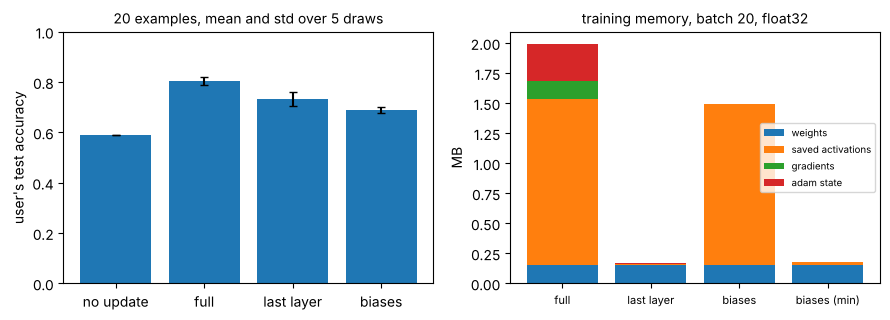

In [3]:
def saved_activation_bytes(mode, batch=20):
    m = copy.deepcopy(model); set_trainable(m, mode)
    weights = {p.untyped_storage().data_ptr() for p in m.parameters()}
    kept = {}
    def pack(t):                                           # called for every tensor autograd saves
        s = t.untyped_storage()
        if s.data_ptr() not in weights:
            kept[s.data_ptr()] = s.nbytes()
        return t
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        F.cross_entropy(m(Xu_pool[:batch]), yu_pool[:batch])
    return sum(kept.values())

rows = []
for mode in ["full", "last layer", "biases"]:
    n_tr = sum(p.numel() for p in set_trainable(copy.deepcopy(model), mode))
    act = saved_activation_bytes(mode)
    rows.append(dict(method=mode, trained_params=n_tr, weights=4 * n_params, saved_activations=act, gradients=4 * n_tr,
                     adam_state=8 * n_tr, total=4 * n_params + act + 12 * n_tr))
# minimum for biases only: 1 bit per ReLU output, 2 bits per max-pool output, plus the 20 x 10 softmax for the loss
B = 20
relu_vals = B * (16 * 16 * 16 + 32 * 8 * 8 + 64); pool_vals = B * (16 * 8 * 8 + 32 * 4 * 4)
minimum = relu_vals // 8 + pool_vals // 4 + B * 10 * 4
rows.append(dict(method="biases, minimum (TinyTL idea)", trained_params=122, weights=4 * n_params, saved_activations=minimum,
                 gradients=4 * 122, adam_state=8 * 122, total=4 * n_params + minimum + 12 * 122))
mem = pd.DataFrame(rows)
print("training memory in bytes, float32, batch of 20")
print(mem.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
names = ["no update", "full", "last layer", "biases"]
ax[0].bar(names, [np.mean(results[k]) for k in names], yerr=[np.std(results[k]) for k in names], color="tab:blue", capsize=3)
ax[0].set_ylabel("user's test accuracy"); ax[0].set_ylim(0, 1); ax[0].set_title("20 examples, mean and std over 5 draws", fontsize=10)
parts = ["weights", "saved_activations", "gradients", "adam_state"]
bottom = np.zeros(len(mem))
for part in parts:
    ax[1].bar(range(len(mem)), mem[part] / 1e6, bottom=bottom, label=part.replace("_", " ")); bottom += mem[part] / 1e6
ax[1].set_xticks(range(len(mem))); ax[1].set_xticklabels(["full", "last layer", "biases", "biases (min)"], fontsize=8)
ax[1].set_ylabel("MB"); ax[1].set_title("training memory, batch 20, float32", fontsize=10); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 4. Federated averaging over five phones
Now five phones each have their own style (rotated left, rotated right and thick, thick, small and shifted, strongly rotated) and their own labelled digits, which never leave the phone. **FedAvg** (McMahan et al. 2017; Course 8 session 5): in each of 10 rounds, every phone downloads the global model, trains it for 2 epochs on its own data, and uploads the result; the server averages the five models. We compare it with each phone training **alone** for the same 20 epochs, and with FedAvg followed by 2 epochs of local fine-tuning. Each phone is tested on 79 of its own held-out digits.

To save mobile data, phones can upload a **compressed update**: the change in the weights, quantized to int8 with one scale per tensor. We run everything with 20 and with 150 labelled digits per phone, three times with fixed seeds.

no update: mean accuracy over the five phones 0.646


 examples_per_phone  seed  alone  fedavg  fedavg_then_local  fedavg_int8_updates
                 20     0  0.711   0.714              0.681                0.714
                 20     1  0.719   0.754              0.800                0.754
                 20     2  0.727   0.744              0.719                0.742
                150     0  0.949   0.868              0.906                0.863
                150     1  0.952   0.873              0.904                0.873
                150     2  0.957   0.863              0.906                0.866

means over the 3 seeds:
                    alone  fedavg  fedavg_then_local  fedavg_int8_updates
examples_per_phone                                                       
20                  0.719   0.738              0.733                0.737
150                 0.953   0.868              0.905                0.868

per phone and round: download 153,128 bytes; upload 153,128 bytes in float32 or 38,314 bytes as an int8 update;

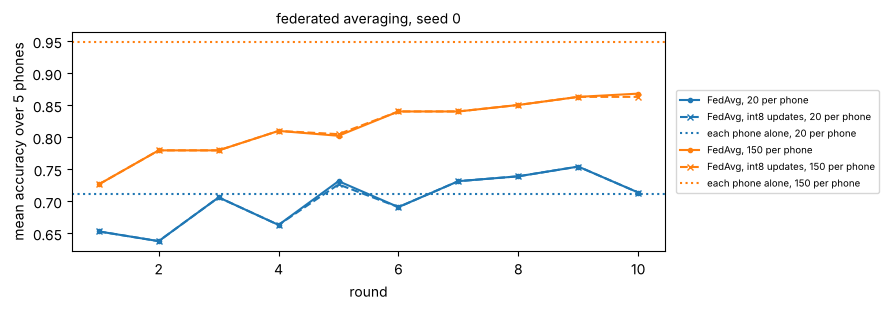

runtime so far 33 s


In [4]:
PHONE_STYLES = [dict(rot=-20), dict(rot=20, thick=2), dict(thick=3), dict(zoom=0.8, shift=(1, 1)), dict(rot=35)]
fl_ids = np.random.default_rng(1).permutation(pool_idx)
phones = []
for k, st in enumerate(PHONE_STYLES):
    ids = fl_ids[229 * k: 229 * (k + 1)]
    Xk, yk = style(X[ids], **st), torch.tensor(y[ids])
    phones.append(dict(Xtr=Xk[:150], ytr=yk[:150], Xte=Xk[150:], yte=yk[150:]))

def local_train(m, Xk, yk, epochs, seed, lr=0.01):
    g = torch.Generator().manual_seed(seed); opt = torch.optim.SGD(m.parameters(), lr, momentum=0.9); m.train()
    for _ in range(epochs):
        p = torch.randperm(len(Xk), generator=g)
        for i in range(0, len(Xk), 16):
            idx = p[i:i + 16]
            loss = F.cross_entropy(m(Xk[idx]), yk[idx]); opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

def mean_phone_accuracy(models):
    return float(np.mean([accuracy(m, ph["Xte"], ph["yte"]) for m, ph in zip(models, phones)]))

def int8_update(delta):                                   # compress an update: int8 values + one float scale
    mx = delta.abs().max()
    return delta if mx == 0 else torch.round(delta / (mx / 127)).clamp(-127, 127) * (mx / 127)

def fedavg(n, seed, compress=False, rounds=10, epochs=2):
    glob, history = copy.deepcopy(model), []
    for rd in range(rounds):
        states = []
        for k, ph in enumerate(phones):
            local = local_train(copy.deepcopy(glob), ph["Xtr"][:n], ph["ytr"][:n], epochs, seed=1000 * seed + 100 * rd + k)
            st, g = local.state_dict(), glob.state_dict()
            states.append({w: g[w] + int8_update(st[w] - g[w]) for w in st} if compress else st)
        glob.load_state_dict({w: sum(s[w] for s in states) / len(states) for w in states[0]})
        history.append(mean_phone_accuracy([glob] * 5))
    return glob, history

print(f"no update: mean accuracy over the five phones {mean_phone_accuracy([model] * 5):.3f}")
rows, curves = [], {}
for n in [20, 150]:
    for seed in range(3):
        alone = mean_phone_accuracy([local_train(copy.deepcopy(model), ph["Xtr"][:n], ph["ytr"][:n], 20, seed=10 * seed + k)
                                     for k, ph in enumerate(phones)])
        g, hist = fedavg(n, seed)
        tuned = mean_phone_accuracy([local_train(copy.deepcopy(g), ph["Xtr"][:n], ph["ytr"][:n], 2, seed=50 * seed + k)
                                     for k, ph in enumerate(phones)])
        g8, hist8 = fedavg(n, seed, compress=True)
        rows.append(dict(examples_per_phone=n, seed=seed, alone=alone, fedavg=hist[-1], fedavg_then_local=tuned, fedavg_int8_updates=hist8[-1]))
        if seed == 0:
            curves[n] = (hist, hist8, alone)
fl = pd.DataFrame(rows)
print(fl.round(3).to_string(index=False))
print("\nmeans over the 3 seeds:")
print(fl.groupby("examples_per_phone")[["alone", "fedavg", "fedavg_then_local", "fedavg_int8_updates"]].mean().round(3).to_string())
model_bytes = 4 * n_params
int8_bytes = n_params + 4 * len(model.state_dict())
print(f"\nper phone and round: download {model_bytes:,} bytes; upload {model_bytes:,} bytes in float32 or {int8_bytes:,} bytes as an int8 update; "
      f"10 rounds: {10 * 2 * model_bytes / 1e6:.2f} MB against {10 * (model_bytes + int8_bytes) / 1e6:.2f} MB")

plt.figure(figsize=(9, 3.2))
for (n, (h, h8, alone)), col in zip(curves.items(), ["tab:blue", "tab:orange"]):
    plt.plot(range(1, 11), h, "o-", color=col, ms=3, label=f"FedAvg, {n} per phone")
    plt.plot(range(1, 11), h8, "x--", color=col, ms=4, label=f"FedAvg, int8 updates, {n} per phone")
    plt.axhline(alone, color=col, ls=":", label=f"each phone alone, {n} per phone")
plt.xlabel("round"); plt.ylabel("mean accuracy over 5 phones"); plt.title("federated averaging, seed 0", fontsize=10)
plt.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 5. Planning the capstone
The capstone puts one model from this programme on a low-cost Android phone and reports honest measurements: for example a small Bangla language model from Course 5, an assistive model from Course 12, or a crop-disease classifier from Course 13. The course document gives the full brief; the plan needs, at least:

1. **the task and the user**, and what "good enough" means (accuracy, latency, offline use);
2. **the phone**: model, RAM, and chip, with its memory budget (session 8);
3. **the model and format**: size, quantization (sessions 3 and 4), runtime and conversion check (session 7);
4. **measurements**: accuracy before and after conversion, file size, peak memory, latency distribution, cold start, battery (session 11);
5. **privacy and updates**: what data stays on the phone, how the model is updated, what is logged.

### 6. Exercises

In [5]:
# TODO: memory against batch size. Training on a phone can use small batches and accumulate gradients over several
# steps. Measure saved_activation_bytes for batch sizes 1, 5 and 20 for each method (change the batch argument), plot
# the total training memory against batch size, and say which method could train on a microcontroller with 256 KB of RAM.
def memory_vs_batch():
    return None          # replace with your code

r = memory_vs_batch()
print("not done yet" if r is None else r)

not done yet


In [6]:
# TODO: personalize after federated learning with the last layer only. Take a FedAvg model trained with 20 examples per
# phone, then on each phone fine-tune only f2 (as in section 2) on its own 20 examples. Compare the mean accuracy with
# "fedavg" and "fedavg_then_local" in the table, and count the bytes each phone must store for its personal layer.
def fedavg_then_last_layer(n=20, seed=0):
    return None          # replace with your code

r = fedavg_then_last_layer()
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the saved run. Every number except the runtime will match yours.)

1. **The user's style broke the model.** On the same 500 digits, accuracy fell from 0.960 in the standard style to 0.588 in the user's rotated, thicker style.
2. **Twenty labelled examples recovered much of it, and updating everything helped most.** On the user's 350 test digits: no update 0.589; full fine-tuning 0.806 (standard deviation 0.016 over the 5 draws); last layer only 0.735 (0.028); biases only 0.690 (0.013). Which 20 digits the user labelled moved the last-layer result between 0.689 and 0.760. The learning rates were chosen once and not tuned, so a better-tuned bias update might close part of the gap; TinyTL adds small extra modules for this reason.
3. **Memory: the last layer is cheap; biases only were not, in PyTorch.** Full fine-tuning needed 1,994,596 bytes: 153,128 of weights, 1,382,084 of saved activations, 153,128 of gradients and 306,256 of Adam state. The last layer alone needed 170,852 bytes, 12 times less, because autograd kept only 9,924 bytes of activations. Biases only needed 1,495,716 bytes: autograd still saved 1,341,124 bytes, keeping the input image, every ReLU output in float32, the convolution inputs and every max-pool index as an 8-byte integer; only the first linear layer's input was dropped. The bias gradients need far less: one bit per ReLU output and two bits per pooling choice give 24,000 bytes, and 178,592 bytes in total. That saving needs a training engine built for it, as in Lin et al. (2022); a general framework will not find it alone.
4. **None of this is too big for a phone.** Even full fine-tuning on a batch of 20 needs about 2 MB here. Exercise 1 asks which method would fit in a microcontroller's 256 KB.
5. **Federated averaging did not beat training alone, except with very little data.** The pretrained model averaged 0.646 over the five phones' own test digits. With 20 labelled digits per phone (means of 3 seeds), each phone alone reached 0.719, FedAvg 0.738 and FedAvg followed by local fine-tuning 0.733. With 150 per phone, each phone alone reached 0.953, far above FedAvg (0.868), and local fine-tuning after FedAvg gave 0.905. One shared model is a compromise across five very different styles, while each phone is tested only on its own style. FedAvg helped only when each phone had too little data to learn alone.
6. **Compressed updates cost nothing here.** Uploading int8 updates instead of float32 models gave the same mean accuracy (0.737 against 0.738 with 20 digits per phone, 0.868 against 0.868 with 150), and cut each upload from 153,128 to 38,314 bytes, so 10 rounds cost each phone 1.91 MB instead of 3.06 MB of mobile data. Updates can still reveal information about the data (Course 8 session 6).
7. **The round-by-round curve is noisy with little data.** With 20 digits per phone, the mean accuracy of FedAvg went up and down from round to round, so the final number depends on when training stops; with 150 digits it rose steadily.